In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
books = pd.read_csv('books.csv', low_memory = False)
users = pd.read_csv('users.csv')
ratings = pd.read_csv('ratings.csv')

In [3]:
books.head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


In [4]:
users.head()

,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


In [5]:
ratings.head()

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [6]:
print(books.shape)
print(users.shape)
print(ratings.shape)


(271360, 8)
(278858, 3)
(1149780, 3)


In [7]:
books.isnull().sum()


ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            3
dtype: int64

In [8]:
users.isnull().sum()

User-ID          0
Location         0
Age         110762
dtype: int64

In [9]:
ratings.isnull().sum()

User-ID        0
ISBN           0
Book-Rating    0
dtype: int64

In [10]:
books.duplicated().sum()

np.int64(0)

In [11]:
users.duplicated().sum()

np.int64(0)

In [12]:
ratings.duplicated().sum()

np.int64(0)

## Popularity Based Recommender System

In [13]:
ratings_with_name = ratings.merge(books, on = 'ISBN')

In [14]:
num_rating_df = ratings_with_name.groupby('Book-Title').count()['Book-Rating'].reset_index()
num_rating_df.rename(columns={'Book-Rating': 'num_ratings'}, inplace=True)
num_rating_df

,Book-Title,num_ratings
0,A Light in the Storm: The Civil War Diary of ...,4
1,Always Have Popsicles,1
2,Apple Magic (The Collector's series),1
3,"Ask Lily (Young Women of Faith: Lily Series, ...",1
4,Beyond IBM: Leadership Marketing and Finance ...,1
...,...,...
241066,Ã?Â?lpiraten.,2
241067,Ã?Â?rger mit Produkt X. Roman.,4
241068,Ã?Â?sterlich leben.,1
241069,Ã?Â?stlich der Berge.,3


In [15]:
avg_rating_df = ratings_with_name.groupby('Book-Title')['Book-Rating'].mean().reset_index()
avg_rating_df.rename(columns={'Book-Rating': 'avg_ratings'}, inplace=True)
avg_rating_df

,Book-Title,avg_ratings
0,A Light in the Storm: The Civil War Diary of ...,2.250000
1,Always Have Popsicles,0.000000
2,Apple Magic (The Collector's series),0.000000
3,"Ask Lily (Young Women of Faith: Lily Series, ...",8.000000
4,Beyond IBM: Leadership Marketing and Finance ...,0.000000
...,...,...
241066,Ã?Â?lpiraten.,0.000000
241067,Ã?Â?rger mit Produkt X. Roman.,5.250000
241068,Ã?Â?sterlich leben.,7.000000
241069,Ã?Â?stlich der Berge.,2.666667


In [16]:
popular_df = num_rating_df.merge(avg_rating_df,on = 'Book-Title')
popular_df

,Book-Title,num_ratings,avg_ratings
0,A Light in the Storm: The Civil War Diary of ...,4,2.250000
1,Always Have Popsicles,1,0.000000
2,Apple Magic (The Collector's series),1,0.000000
3,"Ask Lily (Young Women of Faith: Lily Series, ...",1,8.000000
4,Beyond IBM: Leadership Marketing and Finance ...,1,0.000000
...,...,...,...
241066,Ã?Â?lpiraten.,2,0.000000
241067,Ã?Â?rger mit Produkt X. Roman.,4,5.250000
241068,Ã?Â?sterlich leben.,1,7.000000
241069,Ã?Â?stlich der Berge.,3,2.666667


In [17]:
N= 50
N = min(N, 200)  # safety limit

popular_df = (
    popular_df[popular_df['num_ratings'] >= 250]
    .sort_values('avg_ratings', ascending=False)
    .head(N)
)


In [18]:
Wpopular_df = num_rating_df.merge(avg_rating_df,on = 'Book-Title')
Wpopular_df

,Book-Title,num_ratings,avg_ratings
0,A Light in the Storm: The Civil War Diary of ...,4,2.250000
1,Always Have Popsicles,1,0.000000
2,Apple Magic (The Collector's series),1,0.000000
3,"Ask Lily (Young Women of Faith: Lily Series, ...",1,8.000000
4,Beyond IBM: Leadership Marketing and Finance ...,1,0.000000
...,...,...,...
241066,Ã?Â?lpiraten.,2,0.000000
241067,Ã?Â?rger mit Produkt X. Roman.,4,5.250000
241068,Ã?Â?sterlich leben.,1,7.000000
241069,Ã?Â?stlich der Berge.,3,2.666667


In [19]:
C = Wpopular_df['avg_ratings'].mean()
m = Wpopular_df['num_ratings'].quantile(0.50)  # 75th percentile

In [20]:
# Weighted score
Wpopular_df['weighted_score'] = (
    (Wpopular_df['num_ratings'] / (Wpopular_df['num_ratings'] + m)) * Wpopular_df['avg_ratings']
    + (m / (Wpopular_df['num_ratings'] + m)) * C
)

In [21]:
Wpopular_df = Wpopular_df.sort_values('weighted_score', ascending=False).head(N)

In [22]:
Wpopular_df

,Book-Title,num_ratings,avg_ratings,weighted_score
196050,The Lord of the Rings (Leatherette Collector's...,6,10.000000,8.984305
67636,Flame Of Recca (Flame Of Recca),5,10.000000,8.815023
52247,Dinosaurs: A Celebration,5,10.000000,8.815023
47298,Death: The High Cost of Living,9,9.444444,8.789014
207326,The Shrinking of Treehorn,8,9.500000,8.765571
4462,A Letter to Mrs. Roosevelt,8,9.500000,8.765571
144347,Prometheus Rising,6,9.666667,8.698591
178359,The Blue Day Book: A Lesson in Cheering Yourse...,11,9.181818,8.657511
143822,Principia Discordia,5,9.800000,8.648356
46638,Death : The Time of Your Life (Death),7,9.428571,8.611267


In [23]:
Wpopular_df = Wpopular_df.merge(books, on='Book-Title') \
          .drop_duplicates('Book-Title') \
          [['Book-Title', 'Book-Author', 'Image-URL-M', 'num_ratings', 'avg_ratings','weighted_score']];

In [24]:
Wpopular_df

,Book-Title,Book-Author,Image-URL-M,num_ratings,avg_ratings,weighted_score
0,The Lord of the Rings (Leatherette Collector's...,J. R. R. Tolkien,http://images.amazon.com/images/P/0395193958.0...,6,10.000000,8.984305
1,Flame Of Recca (Flame Of Recca),Nobuyuki Anzai,http://images.amazon.com/images/P/1591161932.0...,5,10.000000,8.815023
6,Dinosaurs: A Celebration,Steve White,http://images.amazon.com/images/P/078510562X.0...,5,10.000000,8.815023
11,Death: The High Cost of Living,Neil Gaiman,http://images.amazon.com/images/P/1563891336.0...,9,9.444444,8.789014
12,The Shrinking of Treehorn,Florence Parry Heide,http://images.amazon.com/images/P/0823401898.0...,8,9.500000,8.765571
13,A Letter to Mrs. Roosevelt,C. COCO DE YOUNG,http://images.amazon.com/images/P/0385326335.0...,8,9.500000,8.765571
14,Prometheus Rising,Robert Anton Wilson,http://images.amazon.com/images/P/1561840564.0...,6,9.666667,8.698591
15,The Blue Day Book: A Lesson in Cheering Yourse...,Bradley Trevor Greive,http://images.amazon.com/images/P/0091842050.0...,11,9.181818,8.657511
16,Principia Discordia,Omar K. Ravenhurst,http://images.amazon.com/images/P/096265342X.0...,5,9.800000,8.648356
17,Death : The Time of Your Life (Death),Neil Gaiman,http://images.amazon.com/images/P/1563893339.0...,7,9.428571,8.611267


In [25]:
popular_df

,Book-Title,num_ratings,avg_ratings
80434,Harry Potter and the Prisoner of Azkaban (Book 3),428,5.852804
80422,Harry Potter and the Goblet of Fire (Book 4),387,5.824289
80441,Harry Potter and the Sorcerer's Stone (Book 1),278,5.737410
80426,Harry Potter and the Order of the Phoenix (Boo...,347,5.501441
80414,Harry Potter and the Chamber of Secrets (Book 2),556,5.183453
191612,The Hobbit : The Enchanting Prelude to The Lor...,281,5.007117
187377,The Fellowship of the Ring (The Lord of the Ri...,368,4.948370
80445,Harry Potter and the Sorcerer's Stone (Harry P...,575,4.895652
211384,"The Two Towers (The Lord of the Rings, Part 2)",260,4.880769
219741,To Kill a Mockingbird,510,4.700000


In [26]:
popular_df = popular_df.merge(books, on='Book-Title') \
          .drop_duplicates('Book-Title') \
          [['Book-Title', 'Book-Author', 'Image-URL-M', 'num_ratings', 'avg_ratings']];

In [27]:
popular_df

,Book-Title,Book-Author,Image-URL-M,num_ratings,avg_ratings
0,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,http://images.amazon.com/images/P/0439136350.0...,428,5.852804
3,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,http://images.amazon.com/images/P/0439139597.0...,387,5.824289
5,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,http://images.amazon.com/images/P/0590353403.0...,278,5.737410
9,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,http://images.amazon.com/images/P/043935806X.0...,347,5.501441
13,Harry Potter and the Chamber of Secrets (Book 2),J. K. Rowling,http://images.amazon.com/images/P/0439064872.0...,556,5.183453
16,The Hobbit : The Enchanting Prelude to The Lor...,J.R.R. TOLKIEN,http://images.amazon.com/images/P/0345339681.0...,281,5.007117
17,The Fellowship of the Ring (The Lord of the Ri...,J.R.R. TOLKIEN,http://images.amazon.com/images/P/0345339703.0...,368,4.948370
26,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling,http://images.amazon.com/images/P/059035342X.0...,575,4.895652
28,"The Two Towers (The Lord of the Rings, Part 2)",J.R.R. TOLKIEN,http://images.amazon.com/images/P/0345339711.0...,260,4.880769
39,To Kill a Mockingbird,Harper Lee,http://images.amazon.com/images/P/0446310786.0...,510,4.700000


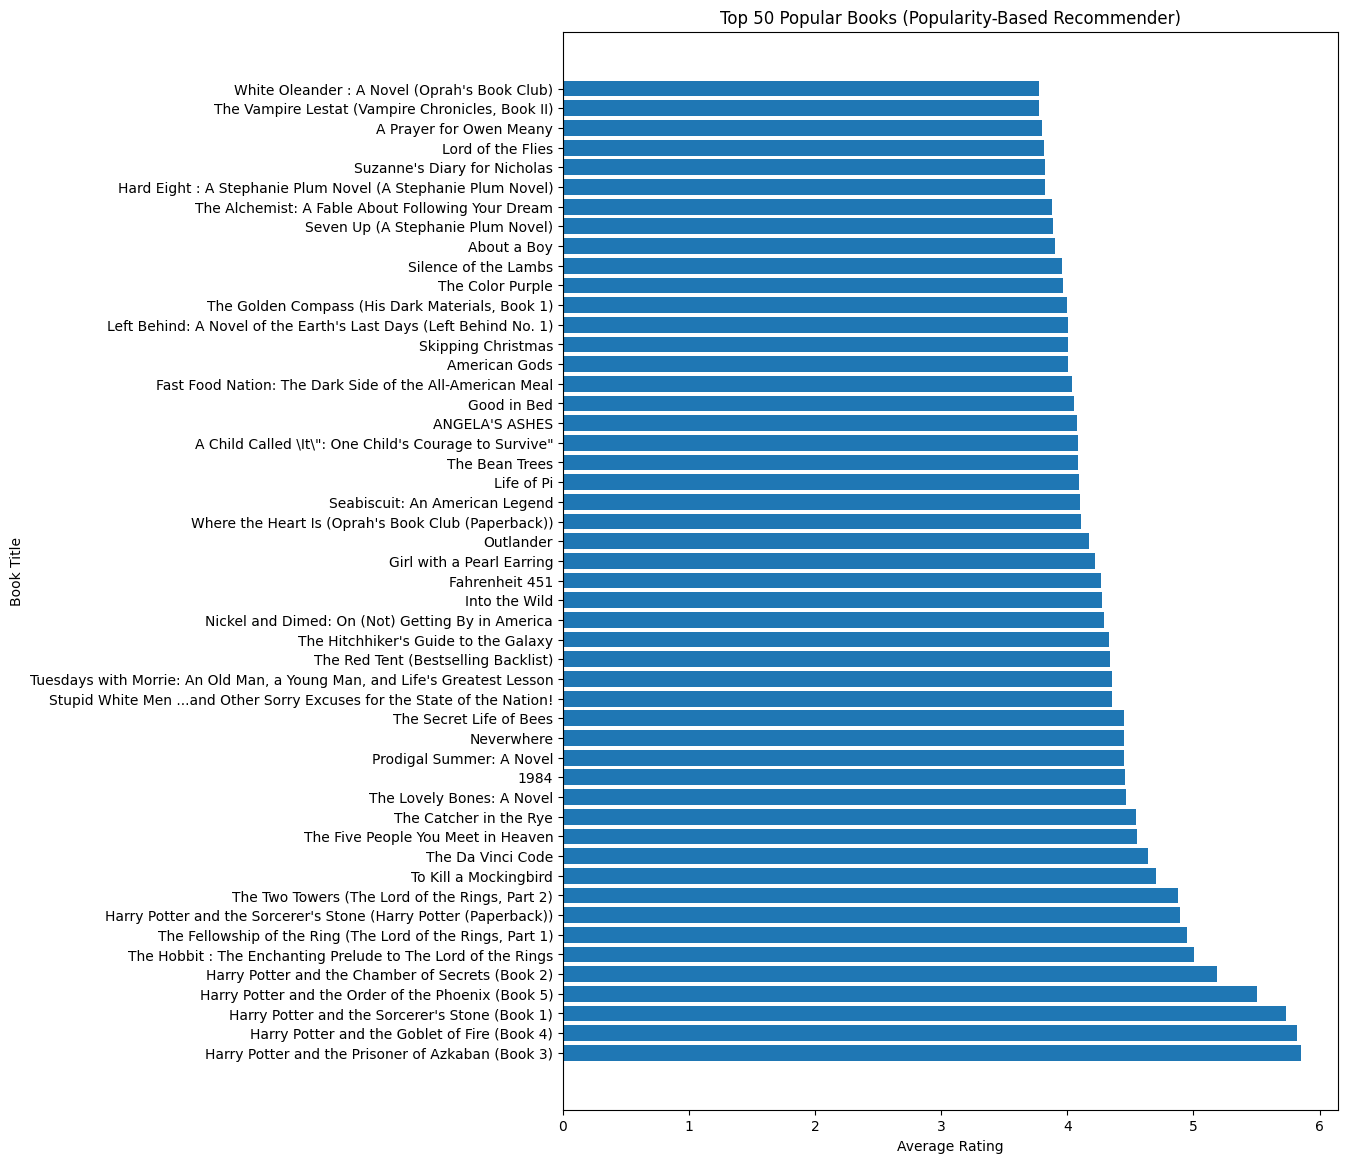

In [28]:
plt.figure(figsize=(10, 14))

plt.barh(
    popular_df.sort_values('avg_ratings')['Book-Title'],
    popular_df.sort_values('avg_ratings')['avg_ratings']
)

plt.xlabel('Average Rating')
plt.ylabel('Book Title')
plt.title('Top 50 Popular Books (Popularity-Based Recommender)')
plt.gca().invert_yaxis()
plt.show()


In [29]:
base_popular_df = num_rating_df.merge(
    avg_rating_df,
    on='Book-Title'
)

In [30]:
books_unique = books.drop_duplicates('Book-Title')

base_popular_df = base_popular_df.merge(
    books_unique[['Book-Title', 'Book-Author', 'Image-URL-M']],
    on='Book-Title',
    how='left'
)


## Collaborative Filtering Based Recommender System

In [31]:
x = ratings_with_name.groupby('User-ID').count()['Book-Rating'] > 200
literate = x[x].index  # Get User-IDs where condition is True

In [32]:
filtered_rating = ratings_with_name[ratings_with_name['User-ID'].isin(literate)]
filtered_rating

,User-ID,ISBN,Book-Rating,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
1150,277427,002542730X,10,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...,http://images.amazon.com/images/P/002542730X.0...
1151,277427,0026217457,0,Vegetarian Times Complete Cookbook,Lucy Moll,1995,John Wiley &amp; Sons,http://images.amazon.com/images/P/0026217457.0...,http://images.amazon.com/images/P/0026217457.0...,http://images.amazon.com/images/P/0026217457.0...
1152,277427,003008685X,8,Pioneers,James Fenimore Cooper,1974,Thomson Learning,http://images.amazon.com/images/P/003008685X.0...,http://images.amazon.com/images/P/003008685X.0...,http://images.amazon.com/images/P/003008685X.0...
1153,277427,0030615321,0,"Ask for May, Settle for June (A Doonesbury book)",G. B. Trudeau,1982,Henry Holt &amp; Co,http://images.amazon.com/images/P/0030615321.0...,http://images.amazon.com/images/P/0030615321.0...,http://images.amazon.com/images/P/0030615321.0...
1154,277427,0060002050,0,On a Wicked Dawn (Cynster Novels),Stephanie Laurens,2002,Avon Books,http://images.amazon.com/images/P/0060002050.0...,http://images.amazon.com/images/P/0060002050.0...,http://images.amazon.com/images/P/0060002050.0...
...,...,...,...,...,...,...,...,...,...,...
1029357,275970,1931868123,0,There's a Porcupine in My Outhouse: Misadventu...,Mike Tougias,2002,Capital Books (VA),http://images.amazon.com/images/P/1931868123.0...,http://images.amazon.com/images/P/1931868123.0...,http://images.amazon.com/images/P/1931868123.0...
1029358,275970,3411086211,10,Die Biene.,Sybil GrÃ?Â¤fin SchÃ?Â¶nfeldt,1993,"Bibliographisches Institut, Mannheim",http://images.amazon.com/images/P/3411086211.0...,http://images.amazon.com/images/P/3411086211.0...,http://images.amazon.com/images/P/3411086211.0...
1029359,275970,3829021860,0,The Penis Book,Joseph Cohen,1999,Konemann,http://images.amazon.com/images/P/3829021860.0...,http://images.amazon.com/images/P/3829021860.0...,http://images.amazon.com/images/P/3829021860.0...
1029360,275970,4770019572,0,Musashi,Eiji Yoshikawa,1995,Kodansha International (JPN),http://images.amazon.com/images/P/4770019572.0...,http://images.amazon.com/images/P/4770019572.0...,http://images.amazon.com/images/P/4770019572.0...


In [33]:
y = filtered_rating.groupby('Book-Title').count()['Book-Rating']>=50
famous_books = y[y].index

In [34]:
final_ratings = filtered_rating[filtered_rating['Book-Title'].isin(famous_books)]

In [35]:
pt = final_ratings.pivot_table(index='Book-Title',columns='User-ID',values='Book-Rating')

In [36]:
pt

User-ID,254,2276,2766,2977,3363,4017,4385,6251,6323,6543,...,271705,273979,274004,274061,274301,274308,275970,277427,277639,278418
Book-Title,,,,,,,,,,,,,,,,,,,,,
1984,9.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,10.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN
1st to Die: A Novel,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2nd Chance,NaN,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,...,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.0,NaN
4 Blondes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A Bend in the Road,0.0,NaN,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Year of Wonders,NaN,NaN,NaN,7.0,NaN,NaN,NaN,NaN,NaN,0.0,...,NaN,9.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN
You Belong To Me,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zen and the Art of Motorcycle Maintenance: An Inquiry into Values,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN


In [37]:
pt.fillna(0, inplace=True)

In [38]:
pt

User-ID,254,2276,2766,2977,3363,4017,4385,6251,6323,6543,...,271705,273979,274004,274061,274301,274308,275970,277427,277639,278418
Book-Title,,,,,,,,,,,,,,,,,,,,,
1984,9.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1st to Die: A Novel,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2nd Chance,0.0,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4 Blondes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A Bend in the Road,0.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Year of Wonders,0.0,0.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,9.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
You Belong To Me,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Zen and the Art of Motorcycle Maintenance: An Inquiry into Values,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [39]:
from sklearn.metrics.pairwise import cosine_similarity

In [40]:
similarity_scores = cosine_similarity(pt)

In [41]:
similarity_scores

array([[1.        , 0.10255025, 0.01220856, ..., 0.12110367, 0.07347567,
        0.04316046],
       [0.10255025, 1.        , 0.2364573 , ..., 0.07446129, 0.16773875,
        0.14263397],
       [0.01220856, 0.2364573 , 1.        , ..., 0.04558758, 0.04938579,
        0.10796119],
       ...,
       [0.12110367, 0.07446129, 0.04558758, ..., 1.        , 0.07085128,
        0.0196177 ],
       [0.07347567, 0.16773875, 0.04938579, ..., 0.07085128, 1.        ,
        0.10602962],
       [0.04316046, 0.14263397, 0.10796119, ..., 0.0196177 , 0.10602962,
        1.        ]], shape=(706, 706))

In [42]:
def recommended(book_name, top_n=5):
    index = np.where(pt.index == book_name)[0][0]

    similar_items = sorted(
        list(enumerate(similarity_scores[index])),
        key=lambda x: x[1],
        reverse=True
    )[:top_n+1]  # include self

    data = []

    for idx, score in similar_items:
        temp_df = books[books['Book-Title'] == pt.index[idx]].drop_duplicates('Book-Title')

        data.append({
            "title": temp_df['Book-Title'].values[0],
            "author": temp_df['Book-Author'].values[0],
            "image_url": temp_df['Image-URL-M'].values[0],
            "cosine_similarity": round(float(score), 4)
        })

    return data


In [43]:
recs = recommended('1984')

In [44]:
recommended('1984')

[{'title': '1984',
  'author': 'George Orwell',
  'image_url': 'http://images.amazon.com/images/P/0451524934.01.MZZZZZZZ.jpg',
  'cosine_similarity': 1.0},
 {'title': 'Animal Farm',
  'author': 'George Orwell',
  'image_url': 'http://images.amazon.com/images/P/0451526341.01.MZZZZZZZ.jpg',
  'cosine_similarity': 0.2703},
 {'title': "The Handmaid's Tale",
  'author': 'Margaret Atwood',
  'image_url': 'http://images.amazon.com/images/P/0449212602.01.MZZZZZZZ.jpg',
  'cosine_similarity': 0.264},
 {'title': 'Brave New World',
  'author': 'Aldous Huxley',
  'image_url': 'http://images.amazon.com/images/P/0060809833.01.MZZZZZZZ.jpg',
  'cosine_similarity': 0.2367},
 {'title': 'The Vampire Lestat (Vampire Chronicles, Book II)',
  'author': 'ANNE RICE',
  'image_url': 'http://images.amazon.com/images/P/0345313860.01.MZZZZZZZ.jpg',
  'cosine_similarity': 0.233},
 {'title': 'The Hours : A Novel',
  'author': 'Michael Cunningham',
  'image_url': 'http://images.amazon.com/images/P/0312243022.01.MZZ

In [45]:
titles = [item['title'] for item in recs]
scores = [item['cosine_similarity'] for item in recs]

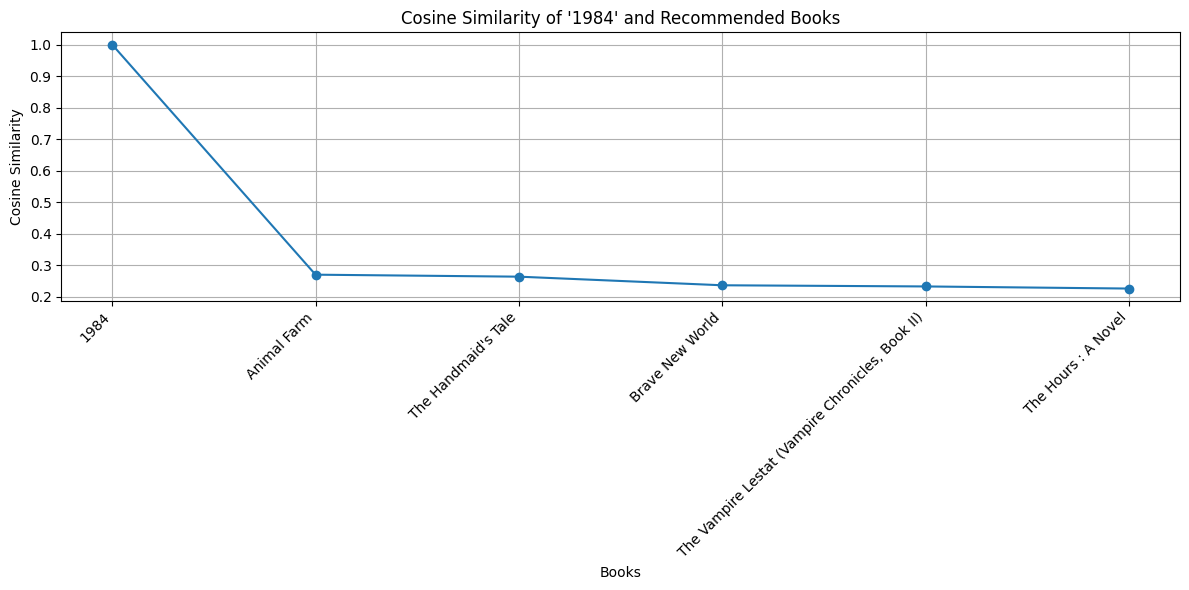

In [46]:
plt.figure(figsize=(12, 6))
plt.plot(titles, scores, marker='o')
plt.xticks(rotation=45, ha='right')
plt.xlabel("Books")
plt.ylabel("Cosine Similarity")
plt.title("Cosine Similarity of '1984' and Recommended Books")
plt.grid(True)
plt.tight_layout()
plt.show()

In [47]:
pt.index[545]

"The Handmaid's Tale"

In [48]:
popular_df['Image-URL-M'][0]

'http://images.amazon.com/images/P/0439136350.01.MZZZZZZZ.jpg'

In [49]:
import pickle
pickle.dump(popular_df,open('popular.pkl','wb'))

In [50]:
popular_df['Image-URL-M'][0]

'http://images.amazon.com/images/P/0439136350.01.MZZZZZZZ.jpg'

In [51]:
pickle.dump(pt,open('pt.pkl','wb'))
pickle.dump(books,open('books.pkl','wb'))
pickle.dump(similarity_scores,open('similarity_scores.pkl','wb'))
pickle.dump(Wpopular_df,open('Wpopular.pkl','wb'))

In [52]:
pickle.dump(Wpopular_df,open('Wpopular.pkl','wb'))

In [53]:
pickle.dump(base_popular_df,open('base_popular_df.pkl','wb'))